# A6 - Dự đoán giá đóng cửa cổ phiếu Amazon bằng RNN (PyTorch)

**Dataset:** `AMZN.csv`  
**Framework:** PyTorch  
**Mô hình:** `RNN + Linear`  
**Bài toán:** dùng **30 phiên giao dịch trước** để dự đoán `Close` của **phiên tiếp theo**.

Quy trình:
1. Load Data
2. Data Understanding
3. Cleaning
4. Visualization / EDA
5. Chọn giai đoạn modeling
6. Train / Validation / Test theo thời gian
7. Scaling chỉ fit trên Train
8. Create Sequences
9. Dataset / DataLoader
10. Build RNN PyTorch
11. Train
12. Training / Validation Loss
13. Predict
14. Inverse Transform
15. Evaluate + Naive Baseline
16. Direction Accuracy
17. Actual vs Predicted
18. Lưu model / kết quả
19. Kết luận

**Bản nộp độc lập:** toàn bộ hàm xử lý dữ liệu, định nghĩa mô hình, huấn luyện
và kiểm tra tải lại đều nằm trong notebook. Không cần các file `.py` của dự án.
Đặt CSV tương ứng cạnh notebook, chọn kernel đã cài thư viện và Restart & Run All.
Chọn checkpoint/cấu hình bằng Validation; Test chỉ dùng để báo cáo cuối cùng.

## 0. Import thư viện

In [1]:
# Nếu cần: %pip install numpy pandas matplotlib scikit-learn torch

from pathlib import Path
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Set before importing a framework; helps deterministic CUDA execution.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
SEED = int(os.environ.get("RNN_SEED", "42"))
np.random.seed(SEED)
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import copy
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", DEVICE, "| Seed:", SEED)

PyTorch: 2.14.0+cpu | Device: cpu | Seed: 42


## 1. Load Data

In [2]:
# Hỗ trợ CSV cạnh notebook hoặc cấu trúc data/ + notebooks/.
candidates = [Path.cwd() / "AMZN.csv",
              Path.cwd() / "data" / "AMZN.csv",
              Path.cwd().parent / "data" / "AMZN.csv"]
DATA_PATH = next((p.resolve() for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Đặt AMZN.csv cạnh notebook hoặc trong thư mục data/.")
PROJECT_ROOT = DATA_PATH.parent.parent if DATA_PATH.parent.name == "data" else DATA_PATH.parent
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
df_raw = pd.read_csv(DATA_PATH)
required_columns = ['Date', 'Open', 'High', 'Low', 'Close', 'Volume']
missing = set(required_columns) - set(df_raw.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")
print("Data:", DATA_PATH)
print("Results:", RESULTS_DIR)
print("Shape:", df_raw.shape)
display(df_raw.head())

Data: D:\A06\data\AMZN.csv
Results: D:\A06\results
Shape: (6684, 7)


,Date,Open,High,Low,Close,Adj Close,Volume
0,1997-05-15,0.121875,0.125000,0.096354,0.097917,0.097917,1443120000
1,1997-05-16,0.098438,0.098958,0.085417,0.086458,0.086458,294000000
2,1997-05-19,0.088021,0.088542,0.081250,0.085417,0.085417,122136000
3,1997-05-20,0.086458,0.087500,0.081771,0.081771,0.081771,109344000
4,1997-05-21,0.081771,0.082292,0.068750,0.071354,0.071354,377064000


## 2. Data Understanding

In [3]:
print("5 dòng đầu:")
display(df_raw.head())

print("\n5 dòng cuối:")
display(df_raw.tail())

print("\nShape:", df_raw.shape)

print("\nInfo:")
df_raw.info()

5 dòng đầu:


,Date,Open,High,Low,Close,Adj Close,Volume
0,1997-05-15,0.121875,0.125000,0.096354,0.097917,0.097917,1443120000
1,1997-05-16,0.098438,0.098958,0.085417,0.086458,0.086458,294000000
2,1997-05-19,0.088021,0.088542,0.081250,0.085417,0.085417,122136000
3,1997-05-20,0.086458,0.087500,0.081771,0.081771,0.081771,109344000
4,1997-05-21,0.081771,0.082292,0.068750,0.071354,0.071354,377064000



5 dòng cuối:


,Date,Open,High,Low,Close,Adj Close,Volume
6679,2023-11-29,147.850006,148.539993,145.970001,146.320007,146.320007,40610900
6680,2023-11-30,144.759995,146.929993,144.330002,146.089996,146.089996,65814000
6681,2023-12-01,146.000000,147.250000,145.550003,147.029999,147.029999,39924600
6682,2023-12-04,145.250000,145.350006,142.809998,144.839996,144.839996,48294200
6683,2023-12-05,143.550003,148.570007,143.130005,146.880005,146.880005,46754800



Shape: (6684, 7)

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6684 entries, 0 to 6683
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       6684 non-null   object 
 1   Open       6684 non-null   float64
 2   High       6684 non-null   float64
 3   Low        6684 non-null   float64
 4   Close      6684 non-null   float64
 5   Adj Close  6684 non-null   float64
 6   Volume     6684 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 365.7+ KB


In [4]:
print("Thống kê mô tả:")
display(df_raw.describe(include="all"))

Thống kê mô tả:


,Date,Open,High,Low,Close,Adj Close,Volume
count,6684,6684.000000,6684.000000,6684.000000,6684.000000,6684.000000,6.684000e+03
unique,6684,NaN,NaN,NaN,NaN,NaN,NaN
top,1997-05-15,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,34.029317,34.439204,33.584667,34.020316,34.020316,1.403786e+08
std,NaN,49.856923,50.442953,49.213548,49.829566,49.829566,1.390747e+08
min,NaN,0.070313,0.072396,0.065625,0.069792,0.069792,9.744000e+06
25%,NaN,2.036875,2.074750,1.994625,2.042500,2.042500,6.716950e+07
50%,NaN,7.123500,7.178000,6.986750,7.104750,7.104750,1.039790e+08
75%,NaN,45.203874,45.475624,44.870125,45.135750,45.135750,1.587810e+08


### Các cột thường gặp
- `Date`
- `Open`
- `High`
- `Low`
- `Close`
- `Adj Close`
- `Volume`

Model cơ bản sử dụng **`Close`** làm target.

## 3. Cleaning

In [5]:
df = df_raw.copy()

print("Missing values:")
display(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce"
)

numeric_cols = [
    "Open",
    "High",
    "Low",
    "Close",
    "Adj Close",
    "Volume"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )

df = df.dropna(
    subset=["Date", "Close"]
).copy()

duplicate_dates = df["Date"].duplicated().sum()

print("Duplicate Date:", duplicate_dates)

df = (
    df.sort_values("Date")
      .drop_duplicates(
          subset=["Date"],
          keep="last"
      )
      .reset_index(drop=True)
)

print("Shape sau cleaning:", df.shape)
print(
    "Khoảng thời gian:",
    df["Date"].min().date(),
    "->",
    df["Date"].max().date()
)

Missing values:


Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64


Duplicate rows: 0
Duplicate Date: 0
Shape sau cleaning: (6684, 7)
Khoảng thời gian: 1997-05-15 -> 2023-12-05


Không tự động xóa outlier bằng IQR vì các mức giá cao/thấp có thể là biến động thật của thị trường.

## 4. Visualization / EDA

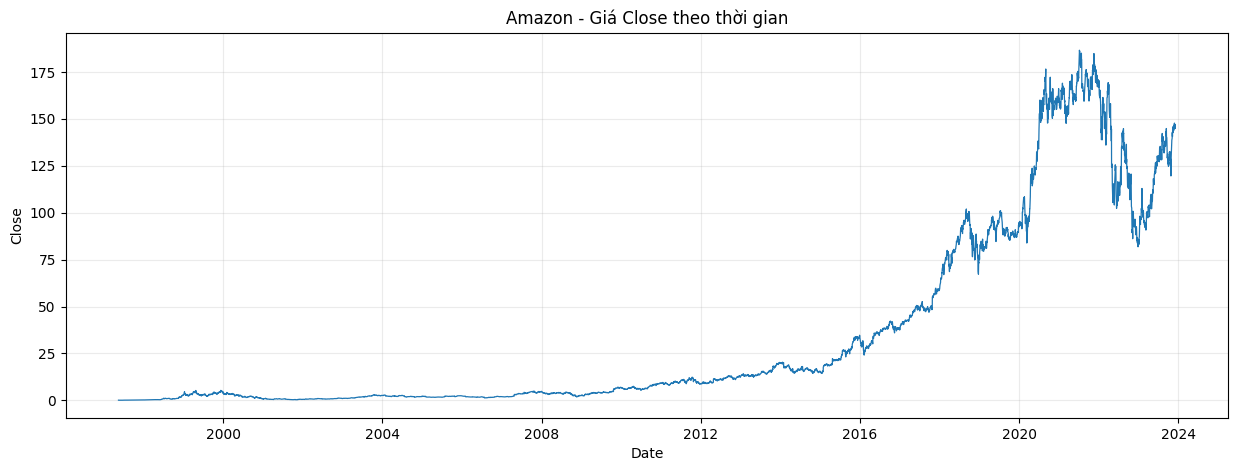

In [6]:
plt.figure(figsize=(15, 5))
plt.plot(df["Date"], df["Close"], linewidth=0.9)
plt.title("Amazon - Giá Close theo thời gian")
plt.xlabel("Date")
plt.ylabel("Close")
plt.grid(alpha=0.25)
plt.show()

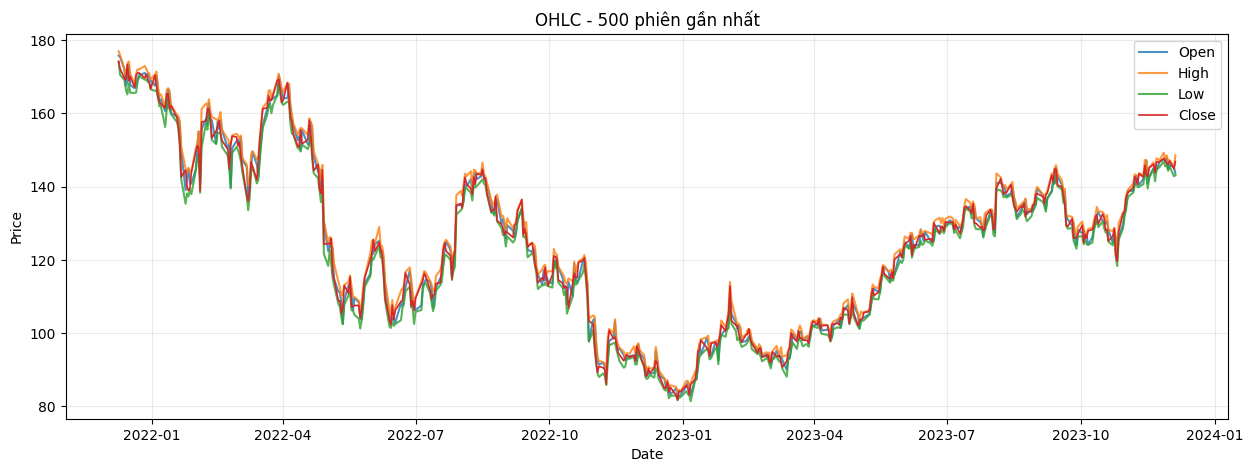

In [7]:
recent_500 = df.tail(500)

plt.figure(figsize=(15, 5))
plt.plot(recent_500["Date"], recent_500["Open"], label="Open", alpha=0.8)
plt.plot(recent_500["Date"], recent_500["High"], label="High", alpha=0.8)
plt.plot(recent_500["Date"], recent_500["Low"], label="Low", alpha=0.8)
plt.plot(recent_500["Date"], recent_500["Close"], label="Close", linewidth=1.2)

plt.title("OHLC - 500 phiên gần nhất")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

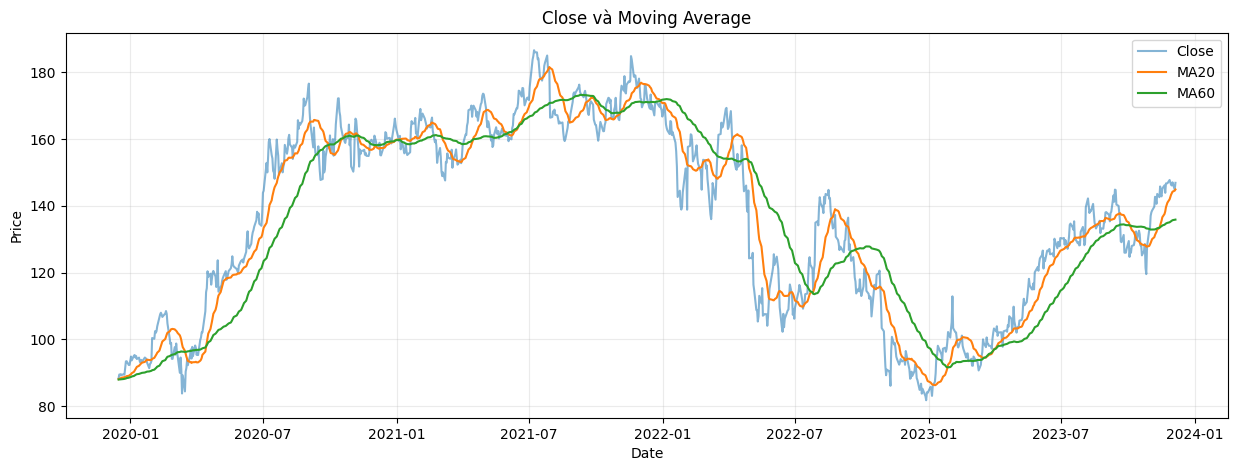

In [8]:
eda = df[["Date", "Close"]].copy()

eda["MA20"] = eda["Close"].rolling(20).mean()
eda["MA60"] = eda["Close"].rolling(60).mean()

recent = eda.tail(1000)

plt.figure(figsize=(15, 5))
plt.plot(recent["Date"], recent["Close"], label="Close", alpha=0.55)
plt.plot(recent["Date"], recent["MA20"], label="MA20")
plt.plot(recent["Date"], recent["MA60"], label="MA60")
plt.title("Close và Moving Average")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

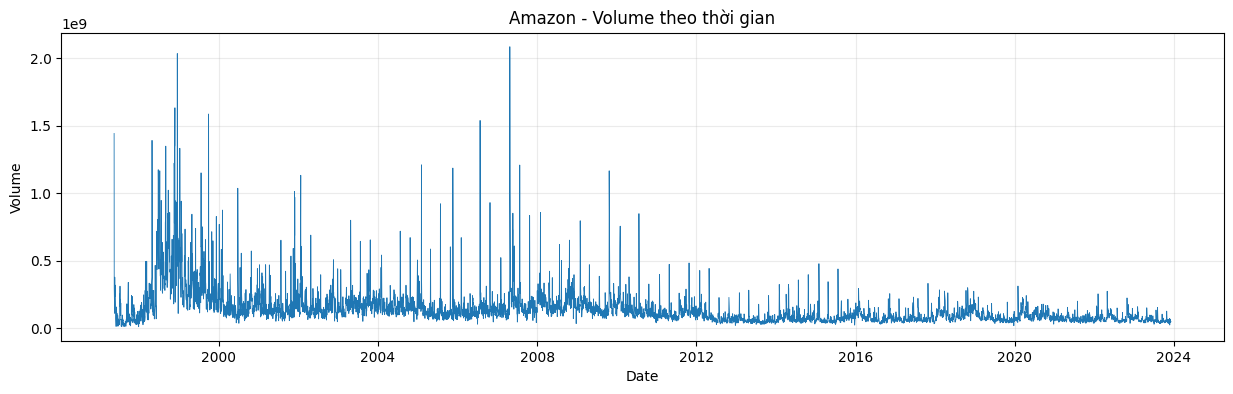

In [9]:
plt.figure(figsize=(15, 4))
plt.plot(df["Date"], df["Volume"], linewidth=0.6)
plt.title("Amazon - Volume theo thời gian")
plt.xlabel("Date")
plt.ylabel("Volume")
plt.grid(alpha=0.25)
plt.show()

count    6683.000000
mean        0.172280
std         3.577751
min       -24.766064
25%        -1.319283
50%         0.044425
75%         1.482147
max        34.471366
Name: Close, dtype: float64

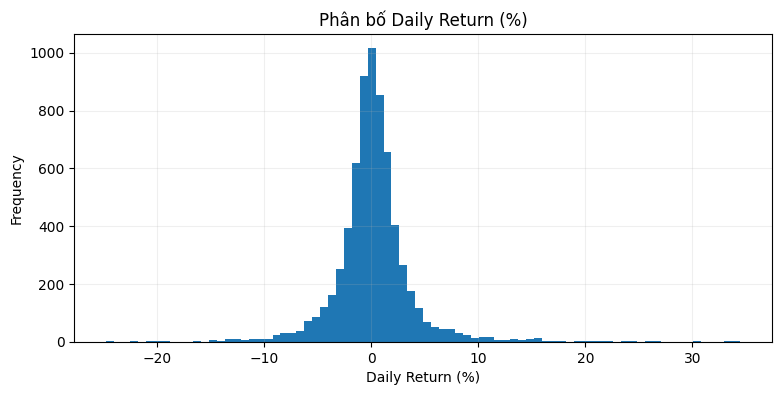

In [10]:
daily_return = (
    df["Close"]
    .pct_change()
    .dropna()
    * 100
)

display(daily_return.describe())

plt.figure(figsize=(9, 4))
plt.hist(daily_return, bins=80)
plt.title("Phân bố Daily Return (%)")
plt.xlabel("Daily Return (%)")
plt.ylabel("Frequency")
plt.grid(alpha=0.2)
plt.show()

## 5. Chọn giai đoạn Modeling

In [11]:
MODEL_START_DATE = "2015-01-01"

model_df = (
    df[df["Date"] >= MODEL_START_DATE][["Date", "Close"]]
    .copy()
    .reset_index(drop=True)
)

print(
    "Modeling period:",
    model_df["Date"].min().date(),
    "->",
    model_df["Date"].max().date()
)

print("Số phiên:", len(model_df))

display(model_df.head())

Modeling period: 2015-01-02 -> 2023-12-05
Số phiên: 2247


,Date,Close
0,2015-01-02,15.4260
1,2015-01-05,15.1095
2,2015-01-06,14.7645
3,2015-01-07,14.9210
4,2015-01-08,15.0230


EDA dùng toàn bộ dữ liệu, nhưng phần modeling dùng từ 2015 trở đi để giảm chênh lệch thang giá quá lớn giữa các giai đoạn rất xa nhau.

## 6. Train / Validation / Test theo thời gian

In [12]:
n = len(model_df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = model_df.iloc[:train_end].copy()
val_df = model_df.iloc[train_end:val_end].copy()
test_df = model_df.iloc[val_end:].copy()

print("Train:", train_df.shape,
      train_df["Date"].min().date(), "->", train_df["Date"].max().date())

print("Validation:", val_df.shape,
      val_df["Date"].min().date(), "->", val_df["Date"].max().date())

print("Test:", test_df.shape,
      test_df["Date"].min().date(), "->", test_df["Date"].max().date())

assert train_df["Date"].max() < val_df["Date"].min()
assert val_df["Date"].max() < test_df["Date"].min()

Train: (1572, 2) 2015-01-02 -> 2021-03-31
Validation: (337, 2) 2021-04-01 -> 2022-08-02
Test: (338, 2) 2022-08-03 -> 2023-12-05


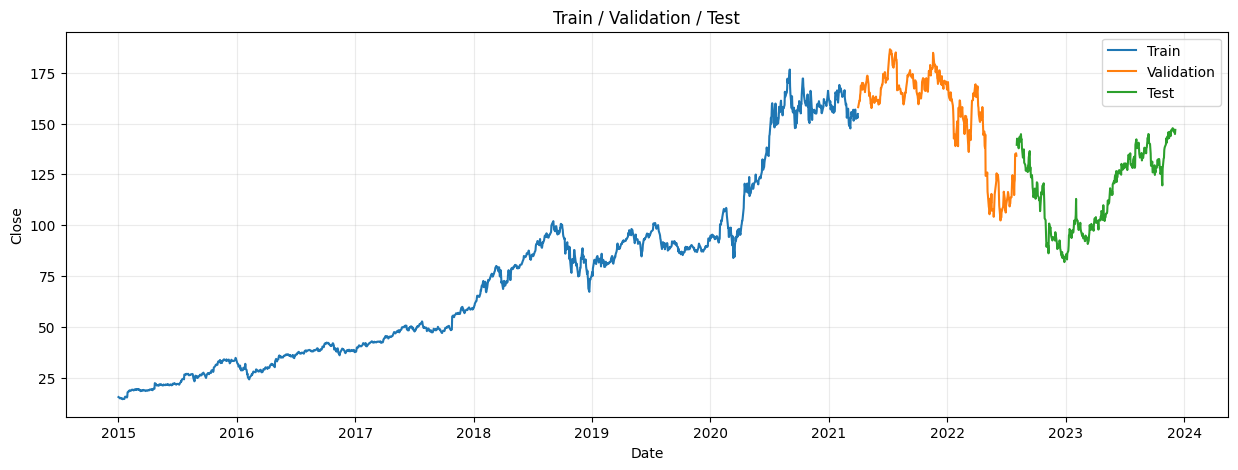

In [13]:
plt.figure(figsize=(15, 5))
plt.plot(train_df["Date"], train_df["Close"], label="Train")
plt.plot(val_df["Date"], val_df["Close"], label="Validation")
plt.plot(test_df["Date"], test_df["Close"], label="Test")
plt.title("Train / Validation / Test")
plt.xlabel("Date")
plt.ylabel("Close")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 7. Scaling

In [14]:
scaler = MinMaxScaler(feature_range=(0, 1))

scaler.fit(
    train_df[["Close"]]
)

train_scaled = scaler.transform(
    train_df[["Close"]]
).reshape(-1)

val_scaled = scaler.transform(
    val_df[["Close"]]
).reshape(-1)

test_scaled = scaler.transform(
    test_df[["Close"]]
).reshape(-1)

all_scaled = scaler.transform(
    model_df[["Close"]]
).reshape(-1)

print(
    "Train scaled:",
    round(train_scaled.min(), 4),
    "->",
    round(train_scaled.max(), 4)
)

print(
    "Validation scaled:",
    round(val_scaled.min(), 4),
    "->",
    round(val_scaled.max(), 4)
)

print(
    "Test scaled:",
    round(test_scaled.min(), 4),
    "->",
    round(test_scaled.max(), 4)
)

Train scaled: 0.0 -> 1.0
Validation scaled: 0.5422 -> 1.0616
Test scaled: 0.4159 -> 0.8222


Scaler chỉ `fit` trên Train để tránh Data Leakage.

## 8. Create Sequences

In [15]:
SEQ_LENGTH = 30

def create_sequences_by_target_range(
    values,
    seq_length,
    target_start,
    target_end
):
    X, y = [], []

    start = max(
        seq_length,
        target_start
    )

    for target_idx in range(
        start,
        target_end
    ):
        X.append(
            values[
                target_idx-seq_length:
                target_idx
            ]
        )

        y.append(
            values[target_idx]
        )

    X = np.asarray(
        X,
        dtype=np.float32
    )

    y = np.asarray(
        y,
        dtype=np.float32
    )

    X = X.reshape(
        X.shape[0],
        X.shape[1],
        1
    )

    return X, y


X_train, y_train = create_sequences_by_target_range(
    all_scaled,
    SEQ_LENGTH,
    SEQ_LENGTH,
    train_end
)

X_val, y_val = create_sequences_by_target_range(
    all_scaled,
    SEQ_LENGTH,
    train_end,
    val_end
)

X_test, y_test = create_sequences_by_target_range(
    all_scaled,
    SEQ_LENGTH,
    val_end,
    n
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (1542, 30, 1)
X_val: (337, 30, 1)
X_test: (338, 30, 1)


Input shape:

```text
(samples, 30, 1)
```

- `30` timesteps
- `1` feature = Close

## 9. Dataset / DataLoader

In [16]:
train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.float32)
)

val_dataset = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.float32)
)

test_dataset = TensorDataset(
    torch.tensor(X_test, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.float32)
)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 49
Validation batches: 11
Test batches: 11


## 10. Build RNN PyTorch

In [17]:
class StockRNN(nn.Module):
    def __init__(self, input_size=1, hidden_size=50, output_size=1):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True, nonlinearity="tanh")
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        _, hidden = self.rnn(x)
        return self.fc(hidden[-1]).squeeze(-1)

model = StockRNN(hidden_size=50).to(DEVICE)
print(model)

StockRNN(
  (rnn): RNN(1, 50, batch_first=True)
  (fc): Linear(in_features=50, out_features=1, bias=True)
)


### Kiến trúc SimpleRNN thuần

```text
30 giá Close đã scale → SimpleRNN(tanh) → Dense/Linear(1) → Close dự đoán
```

Toàn bộ dự đoán được tạo bởi RNN và lớp đầu ra đã huấn luyện.
Không có đường cộng trực tiếp giá phiên trước vào đầu ra.
Chỉ chọn checkpoint sau một epoch huấn luyện trở lên bằng validation MSE.
Persistence (`giá ngày mai = giá hôm nay`) được tính riêng khi đánh giá.
Ba cấu hình thử nghiệm được xác định trước khi xem kết quả Test.

## 11. Loss / Optimizer

In [18]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=4,
    min_lr=1e-5
)

print("Loss: MSE")
print("Optimizer: Adam")

Loss: MSE
Optimizer: Adam


## 12. Train

In [19]:
def run_epoch(model, loader, criterion, optimizer=None):
    model.train(optimizer is not None)
    total_loss, total_samples = 0.0, 0
    with torch.set_grad_enabled(optimizer is not None):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if optimizer is not None:
                optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            if optimizer is not None:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            total_loss += loss.item() * len(yb)
            total_samples += len(yb)
    return total_loss / total_samples

RUN_TUNING = os.environ.get("RNN_TUNE", "1") == "1"
configs = [(32, 0.001), (50, 0.001), (50, 0.0005)] if RUN_TUNING else [(50, 0.001)]
tuning_rows, best_val_mse = [], float("inf")
for units, lr in configs:
    torch.manual_seed(SEED)
    candidate = StockRNN(hidden_size=units).to(DEVICE)
    optimizer = torch.optim.Adam(candidate.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=4, min_lr=1e-5)
    best_loss, best_state, best_epoch = float("inf"), None, None
    patience_counter = 0
    candidate_history = {"train_loss": [], "val_loss": []}
    for epoch in range(80):
        train_loss = run_epoch(candidate, train_loader, criterion, optimizer)
        val_loss = run_epoch(candidate, val_loader, criterion)
        scheduler.step(val_loss)
        candidate_history["train_loss"].append(train_loss)
        candidate_history["val_loss"].append(val_loss)
        if val_loss < best_loss:
            best_loss = val_loss
            best_state = copy.deepcopy(candidate.state_dict())
            best_epoch = epoch + 1
            patience_counter = 0
        else:
            patience_counter += 1
        if patience_counter >= 8:
            break
    if best_state is None:
        raise RuntimeError("No finite validation checkpoint after training")
    candidate.load_state_dict(best_state)
    tuning_rows.append(dict(units=units, learning_rate=lr, val_mse=best_loss, best_epoch=best_epoch, epochs=epoch + 1))
    print(tuning_rows[-1])
    if best_loss < best_val_mse:
        best_val_mse = best_loss
        model, history = candidate, candidate_history
        selected_config = dict(hidden_size=units, learning_rate=lr, best_epoch=best_epoch)
history_df = pd.DataFrame(history)
tuning_df = pd.DataFrame(tuning_rows).sort_values("val_mse")
display(tuning_df)

{'units': 32, 'learning_rate': 0.001, 'val_mse': 0.0006732946366779175, 'best_epoch': 73, 'epochs': 80}
{'units': 50, 'learning_rate': 0.001, 'val_mse': 0.0006815964018909443, 'best_epoch': 70, 'epochs': 78}
{'units': 50, 'learning_rate': 0.0005, 'val_mse': 0.0007997156920198915, 'best_epoch': 78, 'epochs': 80}


,units,learning_rate,val_mse,best_epoch,epochs
0,32,0.0010,0.000673,73,80
1,50,0.0010,0.000682,70,78
2,50,0.0005,0.000800,78,80


## 13. Training / Validation Loss

,train_loss,val_loss
75,0.000210,0.000746
76,0.000170,0.000674
77,0.000185,0.001413
78,0.000183,0.000689
79,0.000143,0.000695


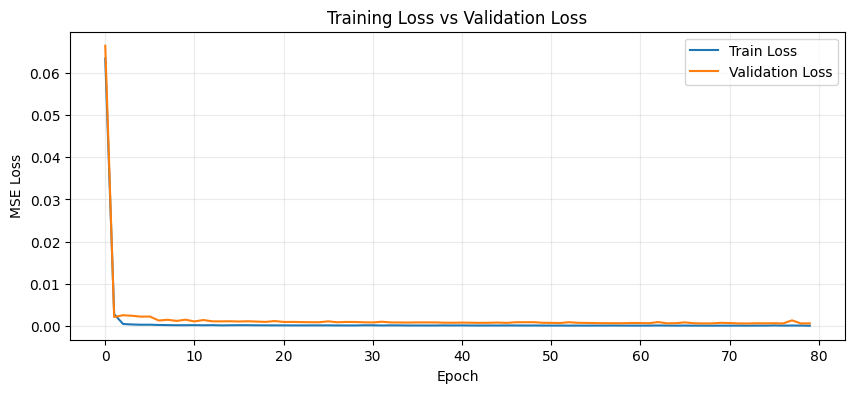

In [20]:
display(history_df.tail())

plt.figure(figsize=(10, 4))

plt.plot(
    history_df["train_loss"],
    label="Train Loss"
)

plt.plot(
    history_df["val_loss"],
    label="Validation Loss"
)

plt.title("Training Loss vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 14. Predict

In [21]:
def predict_loader(
    model,
    loader
):
    model.eval()

    preds_all = []
    targets_all = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(DEVICE)

            pred = model(X_batch)

            preds_all.append(
                pred.cpu().numpy()
            )

            targets_all.append(
                y_batch.numpy()
            )

    return (
        np.concatenate(preds_all),
        np.concatenate(targets_all)
    )


y_pred_scaled, y_test_scaled = predict_loader(
    model,
    test_loader
)

print("Số dự đoán:", len(y_pred_scaled))
print("5 dự đoán đầu:", y_pred_scaled[:5])

Số dự đoán: 338
5 dự đoán đầu: [0.7487644  0.7580861  0.7789247  0.7885734  0.78348756]


## 15. Inverse Transform

In [22]:
y_test_actual = scaler.inverse_transform(
    y_test_scaled.reshape(-1, 1)
).reshape(-1)

y_pred_actual = scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).reshape(-1)

print("5 giá trị thật:")
print(y_test_actual[:5])

print("\n5 dự đoán:")
print(y_pred_actual[:5])

5 giá trị thật:
[139.52 142.57 140.8  139.41 137.83]

5 dự đoán:
[135.8158  137.328   140.70856 142.2738  141.44876]


## 16. Evaluate + Naive Baseline

In [23]:
test_dates = (
    model_df["Date"]
    .iloc[
        val_end:
        val_end + len(y_test_actual)
    ]
    .reset_index(drop=True)
)

prev_close = (
    model_df["Close"]
    .iloc[
        val_end - 1:
        val_end - 1 + len(y_test_actual)
    ]
    .to_numpy()
)

baseline_pred = prev_close.copy()

rnn_mae = mean_absolute_error(
    y_test_actual,
    y_pred_actual
)

rnn_mse = mean_squared_error(
    y_test_actual,
    y_pred_actual
)

rnn_rmse = np.sqrt(rnn_mse)

baseline_mae = mean_absolute_error(
    y_test_actual,
    baseline_pred
)

baseline_mse = mean_squared_error(
    y_test_actual,
    baseline_pred
)

baseline_rmse = np.sqrt(
    baseline_mse
)

metrics_df = pd.DataFrame({
    "Model": [
        "PyTorch SimpleRNN",
        "Naive Baseline"
    ],
    "MAE": [
        rnn_mae,
        baseline_mae
    ],
    "MSE": [
        rnn_mse,
        baseline_mse
    ],
    "RMSE": [
        rnn_rmse,
        baseline_rmse
    ]
})

display(metrics_df)

,Model,MAE,MSE,RMSE
0,PyTorch SimpleRNN,2.492584,10.549297,3.247968
1,Naive Baseline,2.030296,7.292410,2.700446


## 17. Direction Accuracy

In [24]:
actual_change = y_test_actual.astype(np.float64) - prev_close
predicted_change = y_pred_actual.astype(np.float64) - prev_close
actual_direction = np.sign(np.where(np.abs(actual_change) <= 1e-4, 0.0, actual_change))
pred_direction = np.sign(np.where(np.abs(predicted_change) <= 1e-4, 0.0, predicted_change))
direction_accuracy = np.mean(
    actual_direction
    == pred_direction
)

print(
    f"Direction Accuracy: "
    f"{direction_accuracy * 100:.2f}%"
)

if np.isclose(rnn_rmse, baseline_rmse, rtol=0, atol=1e-4):
    print("RNN and persistence have equivalent RMSE within numerical tolerance.")
elif rnn_rmse < baseline_rmse:
    improvement = (
        (baseline_rmse - rnn_rmse)
        / baseline_rmse
        * 100
    )

    print(
        f"RNN RMSE thấp hơn baseline "
        f"{improvement:.2f}%."
    )
else:
    gap = (
        (rnn_rmse - baseline_rmse)
        / baseline_rmse
        * 100
    )

    print(
        f"RNN RMSE cao hơn baseline "
        f"{gap:.2f}%."
    )

    print(
        "Điều này không phải lỗi code. "
        "SimpleRNN có thể chưa vượt được persistence baseline."
    )

direction_table = pd.DataFrame({
    "Direction": ["Down", "Flat", "Up"],
    "Actual_count": [(actual_direction == v).sum() for v in [-1, 0, 1]],
    "Predicted_count": [(pred_direction == v).sum() for v in [-1, 0, 1]]
})
display(direction_table)

Direction Accuracy: 51.18%
RNN RMSE cao hơn baseline 20.28%.
Điều này không phải lỗi code. SimpleRNN có thể chưa vượt được persistence baseline.


,Direction,Actual_count,Predicted_count
0,Down,165,92
1,Flat,2,0
2,Up,171,246


## 18. Actual vs Predicted

In [25]:
result_df = pd.DataFrame({
    "Date": test_dates,
    "Previous_Close": prev_close,
    "Actual_Close": y_test_actual,
    "RNN_Predicted_Close": y_pred_actual,
    "Baseline_Predicted_Close": baseline_pred
})

result_df["RNN_Absolute_Error"] = np.abs(
    result_df["Actual_Close"]
    - result_df["RNN_Predicted_Close"]
)

display(result_df.head(10))

,Date,Previous_Close,Actual_Close,RNN_Predicted_Close,Baseline_Predicted_Close,RNN_Absolute_Error
0,2022-08-03,134.160004,139.520004,135.815796,134.160004,3.704208
1,2022-08-04,139.520004,142.570007,137.328003,139.520004,5.242004
2,2022-08-05,142.570007,140.800003,140.708557,142.570007,0.091446
3,2022-08-08,140.800003,139.410004,142.273804,140.800003,2.863800
4,2022-08-09,139.410004,137.830002,141.448761,139.410004,3.618759
5,2022-08-10,137.830002,142.690002,139.900131,137.830002,2.789871
6,2022-08-11,142.690002,140.639999,140.845398,142.690002,0.205399
7,2022-08-12,140.639999,143.550003,142.077118,140.639999,1.472885
8,2022-08-15,143.550003,143.179993,142.999619,143.550003,0.180374
9,2022-08-16,143.179993,144.779999,143.846436,143.179993,0.933563


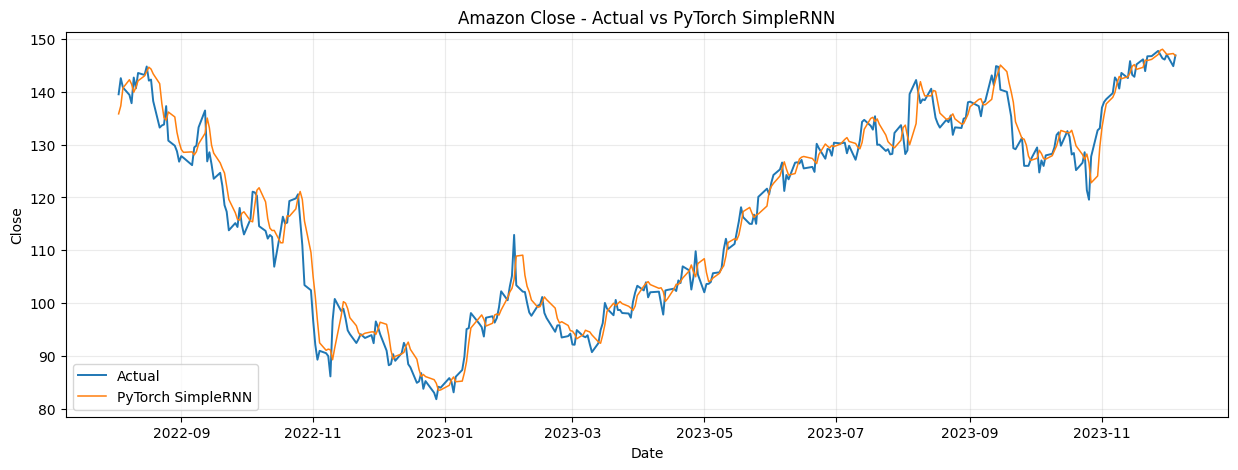

In [26]:
plt.figure(figsize=(15, 5))

plt.plot(
    result_df["Date"],
    result_df["Actual_Close"],
    label="Actual",
    linewidth=1.4
)

plt.plot(
    result_df["Date"],
    result_df["RNN_Predicted_Close"],
    label="PyTorch SimpleRNN",
    linewidth=1.1
)

plt.title("Amazon Close - Actual vs PyTorch SimpleRNN")
plt.xlabel("Date")
plt.ylabel("Close")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

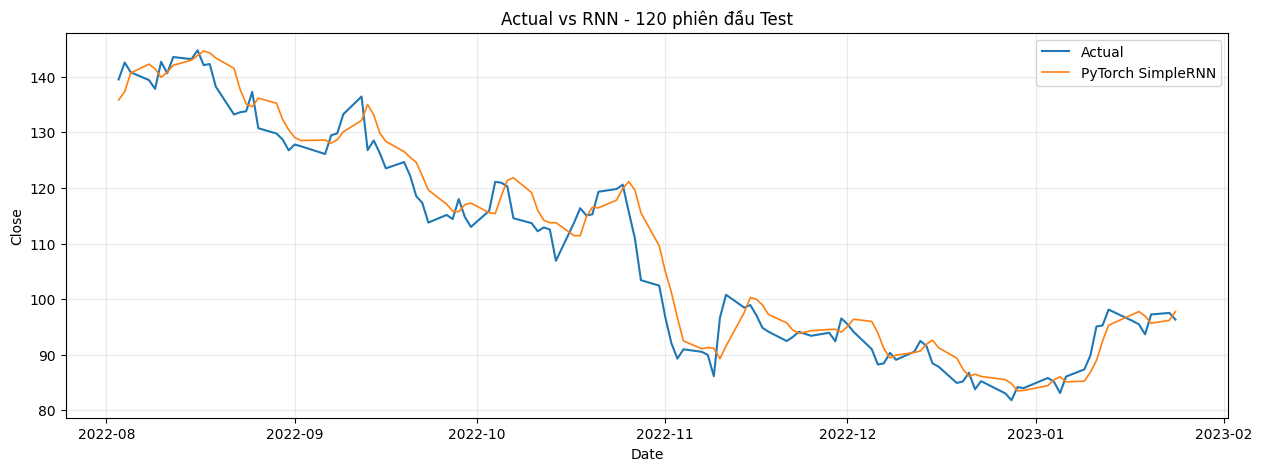

In [27]:
N_PLOT = min(
    120,
    len(result_df)
)

plt.figure(figsize=(15, 5))

plt.plot(
    result_df["Date"].iloc[:N_PLOT],
    result_df["Actual_Close"].iloc[:N_PLOT],
    label="Actual",
    linewidth=1.5
)

plt.plot(
    result_df["Date"].iloc[:N_PLOT],
    result_df["RNN_Predicted_Close"].iloc[:N_PLOT],
    label="PyTorch SimpleRNN",
    linewidth=1.2
)

plt.title(
    f"Actual vs RNN - {N_PLOT} phiên đầu Test"
)

plt.xlabel("Date")
plt.ylabel("Close")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

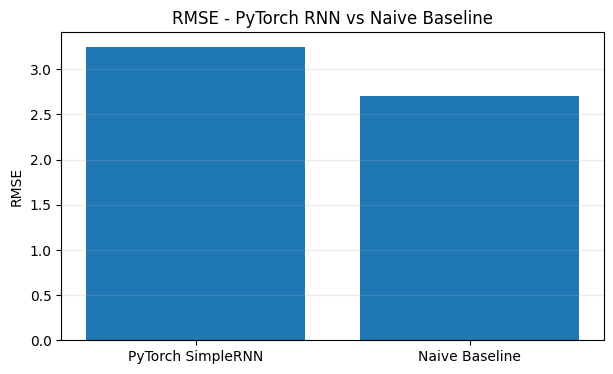

In [28]:
plt.figure(figsize=(7, 4))

plt.bar(
    metrics_df["Model"],
    metrics_df["RMSE"]
)

plt.title("RMSE - PyTorch RNN vs Naive Baseline")
plt.ylabel("RMSE")
plt.grid(axis="y", alpha=0.25)
plt.show()

## 19. Lưu model và kết quả

In [29]:
import hashlib
import importlib.metadata

def save_metadata(path, *, task, framework, seed, seq_length, dataset, **extra):
    digest = hashlib.sha256()
    with Path(dataset).open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    versions = {}
    for name in ("numpy", "pandas", "scikit-learn", "tensorflow", "keras", "torch"):
        try:
            versions[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            pass
    metadata = dict(schema_version=1, task=task, framework=framework, seed=seed,
                    seq_length=seq_length, dataset_sha256=digest.hexdigest(),
                    package_versions=versions, **extra)
    Path(path).write_text(json.dumps(metadata, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
    return metadata

prediction_path = (
    RESULTS_DIR
    / "AMZN_PyTorch_predictions.csv"
)

result_df.to_csv(
    prediction_path,
    index=False
)

model_path = (
    RESULTS_DIR
    / "AMZN_PyTorch_SimpleRNN.pth"
)

torch.save({"model_state_dict": model.state_dict()}, model_path)

print("Predictions:", prediction_path)
print("Model:", model_path)
metadata_extra = dict(**selected_config, selection_metric='val_mse',
    train_samples=len(X_train), validation_samples=len(X_val), test_samples=len(X_test))

metadata_extra.update(architecture="simple_rnn", scaler={
    "scale": scaler.scale_.tolist(), "min": scaler.min_.tolist(),
    "data_min": scaler.data_min_.tolist(), "data_max": scaler.data_max_.tolist()},
    split_dates={"train_end": str(train_df.Date.max()), "val_start": str(val_df.Date.min()),
                 "val_end": str(val_df.Date.max()), "test_start": str(test_df.Date.min())},
    test_metrics={"mae": float(rnn_mae), "rmse": float(rnn_rmse),
                  "baseline_rmse": float(baseline_rmse), "direction_accuracy": float(direction_accuracy)})
tuning_df.to_csv(RESULTS_DIR / "AMZN_PyTorch_validation_search.csv", index=False)
metrics_df.to_csv(RESULTS_DIR / "AMZN_PyTorch_metrics.csv", index=False)

metadata_extra["selected_val_mse"] = float(best_val_mse)
metadata_extra["trained_checkpoint_only"] = True

save_metadata(model_path.with_suffix(".json"), task="stock", framework="pytorch",
              seed=SEED, seq_length=SEQ_LENGTH, dataset=DATA_PATH, **metadata_extra)
history_df.to_csv(RESULTS_DIR / "AMZN_PyTorch_history.csv", index=False)

Predictions: D:\A06\results\AMZN_PyTorch_predictions.csv
Model: D:\A06\results\AMZN_PyTorch_SimpleRNN.pth


## 20. Kết luận

In [30]:
print("===== KẾT QUẢ CUỐI =====")

print(
    f"Modeling period : "
    f"{model_df['Date'].min().date()} "
    f"-> {model_df['Date'].max().date()}"
)

print(f"Sequence length : {SEQ_LENGTH} phiên")
print(f"Train samples   : {len(X_train):,}")
print(f"Validation      : {len(X_val):,}")
print(f"Test samples    : {len(X_test):,}")

print()
print(f"RNN MAE         : {rnn_mae:.4f}")
print(f"RNN MSE         : {rnn_mse:.4f}")
print(f"RNN RMSE        : {rnn_rmse:.4f}")
print(
    f"Direction Acc.  : "
    f"{direction_accuracy * 100:.2f}%"
)

print()
print(f"Baseline RMSE   : {baseline_rmse:.4f}")

===== KẾT QUẢ CUỐI =====
Modeling period : 2015-01-02 -> 2023-12-05
Sequence length : 30 phiên
Train samples   : 1,542
Validation      : 337
Test samples    : 338

RNN MAE         : 2.4926
RNN MSE         : 10.5493
RNN RMSE        : 3.2480
Direction Acc.  : 51.18%

Baseline RMSE   : 2.7004


### Cách diễn giải kết quả

- Đây là dự đoán một phiên tiếp theo, dùng 30 giá lịch sử thực đã biết.
- Model chính là SimpleRNN thuần đã train, chọn bằng Validation MSE.
- Baseline persistence là đối chứng độc lập, không thay thế đầu ra RNN.
- Nếu RNN có RMSE cao hơn baseline: chưa có bằng chứng RNN tạo ra lợi ích
  dự báo vượt persistence trên tập Test này. Không kết luận model đã học
  được xu hướng chỉ vì hai đường trên biểu đồ trông gần nhau.
- Direction Accuracy cần đọc cùng tỷ lệ dự đoán tăng/giảm/không đổi.
- Đây là một seed và một holdout; LSTM/GRU, thêm OHLCV hoặc nhiều seed
  là các thí nghiệm tiếp theo, chưa phải cải thiện đã được chứng minh.

In [31]:
# Tải lại trực tiếp bằng framework và JSON; không cần file Python ngoài.
saved_metadata = json.loads(model_path.with_suffix(".json").read_text(encoding="utf-8"))
loaded_model = StockRNN(hidden_size=saved_metadata["hidden_size"])

checkpoint = torch.load(model_path, map_location="cpu", weights_only=True)
loaded_model.load_state_dict(checkpoint["model_state_dict"])
loaded_model.eval()

def predict_saved_closes(windows):
    raw = np.asarray(windows, dtype=np.float64)
    if raw.ndim == 1:
        raw = raw[None, :]
    if raw.ndim != 2 or raw.shape[1] != saved_metadata["seq_length"] or not np.isfinite(raw).all():
        raise ValueError("Expected finite closing-price windows with the saved sequence length")
    scale = saved_metadata["scaler"]["scale"][0]
    offset = saved_metadata["scaler"]["min"][0]
    values = (raw * scale + offset).astype(np.float32)[..., None]
    with torch.no_grad():
        scaled = loaded_model(torch.from_numpy(values)).numpy().reshape(-1)

    return (scaled - offset) / scale

raw_windows = np.stack([model_df.Close.to_numpy()[i-SEQ_LENGTH:i] for i in range(val_end, n)])
np.testing.assert_allclose(predict_saved_closes(raw_windows), y_pred_actual, rtol=1e-5, atol=1e-4)
print("PASS: reloaded model + scaler reproduce all test predictions.")

PASS: reloaded model + scaler reproduce all test predictions.
